# Лабораторна робота 1

Записник містить 3 розділи з описом та кодом для виконання кожного завдання з лабораторної роботи:

1.   [Теоретичні ймовірності завантаження каналів](#scrollTo=43790354e49fbccf)
2.   [Розв'язок рівнянь Колмогорова](#scrollTo=92e51d6841e7b477)
3.   [Імітаційна модель](#scrollTo=8a77807f92f26ee)

Код кожного з розділів має виконуватись послідовно. Або можна запустити виконання всього записника одразу.

# 1. Теоретичні ймовірності завантаження каналів

Програма обчислює теоретичні ймовірності *p<sub>k</sub>(t)* завантаження *n* каналів за формулою Ерланга.

Вхідні параметри:
- `arrival_rate` - інтенсивність вхідного потоку *$\lambda$*
- `service_rate` - інтенсивність потоку обслуговування *$\mu$*
- `channel_count` - кількість каналів обслуговування *n*

В кінці виконання програма виводить на екран таблицю з наступними результатами:
- стан завантаження каналів (*Channel State*)
- ймовірність стану завантаження каналів (*Channel State Probability*)

In [ ]:
import math
from tabulate import tabulate

arrival_rate = 0.04
service_rate = 0.5
channel_count = 3
utilization_ratio = arrival_rate / service_rate


def erlang_formula_ratio(channel_state):
    return utilization_ratio ** channel_state / math.factorial(channel_state)


def erlang_formula(channel_state):
    return (erlang_formula_ratio(channel_state)
            / (sum([erlang_formula_ratio(inner_channel_state) for inner_channel_state in range(0, channel_count + 1)])))


channel_state_probabilities = [[channel_state,
                                erlang_formula(channel_state)] for channel_state in range(0, channel_count + 1)]

print(tabulate(channel_state_probabilities, headers=['Channel State', 'Channel State Probability']))

  Channel State    Channel State Probability
---------------  ---------------------------
              0                  0.923118
              1                  0.0738494
              2                  0.00295398
              3                  7.87727e-05


# 2. Розв'язок рівнянь Колмогорова

Програма знаходить чисельні розв'язки відповідної системи рівнянь Колмогорова та будує їх графік на заданому інтервалі.

Вхідні параметри:
- `arrival_rate` - інтенсивність вхідного потоку *$\lambda$*
- `service_rate` - інтенсивність потоку обслуговування *$\mu$*
- `channel_count` - кількість каналів обслуговування *n*
- `start_interval` - початковий інтервал для знаходження чисельних розв'язків системи
- `stop_interval` - кінцевий інтервал для знаходження чисельних розв'язків системи (якщо на заданому інтервалі необхідна точність `error` не досягається, то збільшити значення `stop_interval`)
- `interval_count` - кількість точок для знаходження чисельних розв'язків системи
- `error` - допустима похибка між теоретичним значення та чисельним розв'язком

В кінці виконання програма виводить на екран:
- приблизний час, коли чисельні розв'язки починають збігатися до теоретичних значень із похибкою `error` (*Approximate solution time*)
- таблицю з наступними результатами:
  - стан завантаження каналів (*Channel State*)
  - теоретична ймовірність стану завантаження каналів (*Channel State Probability*)
  - чисельна ймовірність стану завантаження каналів (*Channel State Numerical Probability*)
  - похибка обчислення (*Channel State Probability Error*)
- графік чисельних розв'язків системи на заданому інтервалі

Approximate solution time 5.0
  Channel State    Channel State Probability    Channel State Numerical Probability    Channel State Probability Error
---------------  ---------------------------  -------------------------------------  ---------------------------------
              0                  0.923118                               0.929199                           0.0060807
              1                  0.0738494                              0.0682344                          0.00561505
              2                  0.00295398                             0.0025056                          0.000448375
              3                  7.87727e-05                            6.14964e-05                        1.72763e-05


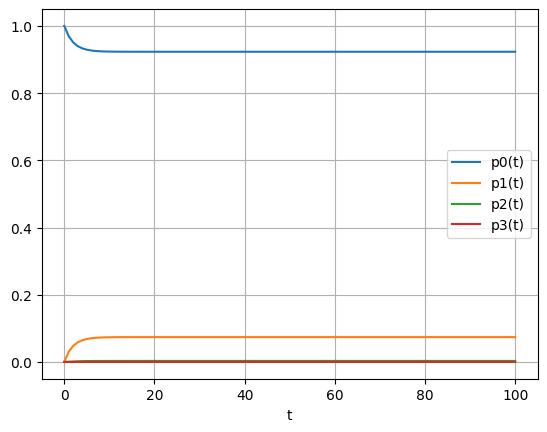

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from tabulate import tabulate

arrival_rate = 0.04
service_rate = 0.5
channel_count = 3
start_interval = 0
stop_interval = 100
interval_count = 101
error = 0.01


def equations(y, t):
    p = y
    dydt = [-arrival_rate * p[0] + service_rate * p[1]]
    for k in range(1, channel_count):
        dydt.append(
            arrival_rate * p[k - 1] - (arrival_rate + k * service_rate) * p[k] + (k + 1) * service_rate * p[k + 1])
    dydt.append(arrival_rate * p[channel_count - 1] - channel_count * service_rate * p[channel_count])
    return dydt


initial_values = [1.0]
for i in range(1, channel_count + 1):
    initial_values.append(0.0)

t = np.linspace(start_interval, stop_interval, interval_count)
solution = odeint(equations, initial_values, t)
tmin = 0
for i in range(len(solution)):
    errori = max([abs(channel_state_probabilities[channel_state][1] - solution[i, channel_state])
        for channel_state in range(0, channel_count + 1)])
    if errori < error:
        tmin = i
        break
print('Approximate solution time ' + str(t[tmin]))
channel_state_numerical_probabilities = [[channel_state,
                                          channel_state_probabilities[channel_state][1],
                                          solution[tmin, channel_state],
                                          abs(channel_state_probabilities[channel_state][1] - solution[
                                              tmin, channel_state])] for channel_state in
                                         range(0, channel_count + 1)]
print(tabulate(channel_state_numerical_probabilities, headers=['Channel State',
                                                               'Channel State Probability',
                                                               'Channel State Numerical Probability',
                                                               'Channel State Probability Error']))

for i in range(0, channel_count + 1):
    plt.plot(t, solution[:, i], label='p' + str(i) + '(t)')
plt.legend(loc='best')
plt.xlabel('t')
plt.grid()
plt.show()

# 3. Імітаційна модель

Імітаційна модель реалізує роботу багатоканальної СМО з відмовами.

Вхідні параметри:
- `arrival_rate` - інтенсивність вхідного потоку *$\lambda$*
- `service_rate` - інтенсивність потоку обслуговування *$\mu$*
- `channel_count` - кількість каналів обслуговування *n*
- `simulation_time` - тривалість модельного часу програми імітаційної моделі
- `simulation_run_count` - кількість запусків програми імітаційної моделі

В кінці виконання програми імітаційної моделі виводить на екран таблицю з наступними результатами:
- стан завантаження каналів (*Channel State*)
- теоретична ймовірність стану завантаження каналів (*Channel State Probability*)
- вибіркове середнє стану завантаження каналів (*Channel State Time Mean*)
- вибіркова дисперсія стану завантаження каналів (*Channel State Time Variance*)
- похибка обчислення (*Channel State Probability Error*)

In [ ]:
import math
import numpy as np
import random
import statistics as st
from tabulate import tabulate

arrival_rate = 0.04
service_rate = 0.5
channel_count = 3
simulation_time = 1000
simulation_run_count = 20


def generate_exponential_random_value(mean):
    return - math.log(random.random()) / mean


def simulate_queue():
    service_time_per_channel_count = [0] * (channel_count + 1)
    busy_channel_count = 0
    previous_time = 0
    arrival_time = 0
    service_time = 0
    arrival_time += generate_exponential_random_value(arrival_rate)
    service_time += generate_exponential_random_value(service_rate)
    next_time = min(arrival_time, service_time)
    while next_time < simulation_time:
        service_time_per_channel_count[busy_channel_count] += next_time - previous_time
        if next_time == service_time:
            service_time += generate_exponential_random_value(service_rate)
            if busy_channel_count > 0:
                busy_channel_count -= 1
        else:
            arrival_time += generate_exponential_random_value(arrival_rate)
            if busy_channel_count < channel_count:
                busy_channel_count += 1
        previous_time = next_time
        next_time = min(arrival_time, service_time)
    channel_state_rate = list(
        map(lambda channel_service_time: channel_service_time / simulation_time, service_time_per_channel_count))
    return channel_state_rate


def calculate_simulation_statistics(channel_state, channel_state_rates):
    mean = st.mean(channel_state_rates)
    variance = st.variance(channel_state_rates, mean)
    return [channel_state, channel_state_probabilities[channel_state][1], mean,
            variance, abs(channel_state_probabilities[channel_state][1] - mean)]


simulation_runs_list = [simulate_queue() for i in range(simulation_run_count)]
simulation_runs_array = np.array(simulation_runs_list)
simulation_statistics = [calculate_simulation_statistics(channel_state, simulation_runs_array[:, channel_state]) for
                         channel_state in range(0, channel_count + 1)]
print(tabulate(simulation_statistics,
               headers=['Channel State', 'Channel State Probability', 'Channel State Time Mean',
                        'Channel State Time Variance', 'Channel State Probability Error']))


  Channel State    Channel State Probability    Channel State Time Mean    Channel State Time Variance    Channel State Probability Error
---------------  ---------------------------  -------------------------  -----------------------------  ---------------------------------
              0                  0.923118                    0.920264                      0.000306263                        0.00285363
              1                  0.0738494                   0.0739166                     0.000240969                        6.71701e-05
              2                  0.00295398                  0.00402858                    9.81779e-06                        0.00107461
              3                  7.87727e-05                 0.00020842                    4.95261e-07                        0.000129647
